In [38]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.3 MB 7.1 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.3 MB 6.4 MB/s eta 0:00:01
   --------------- ------------------------ 3.1/8.3 MB 7.4 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 5.6 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.3 MB 5.7 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 5.7 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 5.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
    --------------------------------------- 0.8/36.7 MB 3.7 MB/s eta 0:00:10
   -- ------------------------------------- 2.6/36.7 MB 6.6 MB/s eta 0:00:06
   ----- ---------------------------------- 4.7/36.7 MB 7.5 MB/s eta 0:00:05
   ------ ------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report,make_scorer

In [3]:
df = pd.read_csv("HR_Job_Placement_Dataset.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Rows and columns:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Rows and columns: (51500, 26)
Number of rows: 51500
Number of columns: 26


In [5]:
df.head()


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [6]:
df.value_counts()

age_years  gender  ssc_percentage  hsc_percentage  degree_percentage  degree_specialization   technical_score  aptitude_score  communication_score  skills_match_percentage  certifications_count  internship_experience  years_of_experience  career_switch_willingness  relevant_experience  previous_ctc_lpa  expected_ctc_lpa  company_tier  job_role_match  competition_level  bond_requirement  notice_period_days  layoff_history  employment_gap_months  relocation_willingness  status    
29         Male    57.077819       69.710840       76.949597          Mechanical              59.043077        52.091106       88.421050            57.375190                1                     Yes                    2                    Not Willing                Relevant             2.604476          8.149780          Tier 2        Matched         High               Not Required      15.0                No              0.0                    Willing                 Not Placed    2
31         Male    63.59883

In [7]:
df.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status'],
      dtype='str')

In [8]:
df.info()
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  str    
 14  r

In [9]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})
missing_report = (
    missing_report[missing_report["Missing_Count"] > 0]
    .sort_values("Missing_Count", ascending=False)
)
print(missing_report.to_string())

                           Missing_Count  Missing_Percentage
relocation_willingness              8475               16.46
layoff_history                      8467               16.44
career_switch_willingness           8466               16.44
relevant_experience                 8426               16.36
job_role_match                      6131               11.90
ssc_percentage                      2581                5.01
hsc_percentage                      2065                4.01
notice_period_days                  1582                3.07
employment_gap_months               1097                2.13


In [10]:
print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate candidate records:",
    df["age_years"].duplicated().sum()
)

Exact duplicate rows: 1376
Duplicate candidate records: 51486


In [11]:
print(df.columns.tolist())
print("Target exists:", "status" in df.columns)
print("Exact duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].head(10)

['age_years', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_specialization', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'internship_experience', 'years_of_experience', 'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'notice_period_days', 'layoff_history', 'employment_gap_months', 'relocation_willingness', 'status']
Target exists: True
Exact duplicate rows: 1376


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
44,34,Male,85.478485,68.494616,82.030799,Computer Science,55.722055,64.300891,98.960728,79.363751,...,7.009318,Tier 1,Not Matched,Medium,Not Required,15.0,NaN,0.0,NaN,Not Placed
137,30,Male,NaN,70.153560,59.278010,Mechanical,100.000000,68.569247,65.584603,88.418583,...,5.818512,Tier 1,Matched,Medium,Not Required,90.0,NaN,0.0,Willing,Placed
143,29,Male,57.077819,69.710840,76.949597,Mechanical,59.043077,52.091106,88.421050,57.375190,...,8.149780,Tier 2,Matched,High,Not Required,15.0,No,0.0,Willing,Not Placed
188,33,Female,74.876729,58.335365,62.501946,Electronics,49.740620,56.307519,65.876841,61.763459,...,6.739745,Tier 3,Matched,Low,Not Required,15.0,NaN,0.0,Willing,Not Placed
197,30,Male,65.502968,78.837258,73.442929,Mechanical,57.478444,40.000000,77.855056,59.302990,...,9.724409,Tier 3,Matched,Medium,Not Required,15.0,No,0.0,Willing,Not Placed
211,30,Female,77.620738,94.274479,78.783687,Electronics,74.072475,60.449747,52.236076,77.448503,...,4.409413,Tier 2,Matched,Low,Not Required,30.0,No,0.0,Willing,Placed
230,31,Male,63.598839,70.665126,72.334421,Information Technology,49.416278,73.801208,79.081967,76.541313,...,12.607601,Tier 2,Matched,Low,Not Required,30.0,No,6.0,Willing,Not Placed
254,21,Male,52.657182,85.933169,78.696122,Others,68.567372,70.541095,53.464032,62.612340,...,11.747651,Tier 3,Matched,High,Not Required,30.0,No,3.0,Willing,Not Placed
282,21,Female,84.985068,61.809077,80.775402,Computer Science,58.290820,63.236548,62.185835,55.685371,...,9.392407,Tier 1,Matched,High,Not Required,0.0,Yes,3.0,Willing,Not Placed
295,26,Female,72.828614,66.165911,75.229417,Mechanical,55.149944,55.682692,60.598152,80.593037,...,3.000000,Tier 3,NaN,High,Not Required,90.0,No,0.0,Willing,Not Placed


In [12]:
print("Duplicate occurrences:", df.duplicated().sum())
print("Rows in duplicate groups:", df.duplicated(keep=False).sum())
print("\nStatus counts:")
print(df["status"].value_counts(dropna=False))
print("\nStatus percentages:")
print(
    (df["status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Duplicate occurrences: 1376
Rows in duplicate groups: 2752

Status counts:
status
Not Placed    35921
Placed        15579
Name: count, dtype: int64

Status percentages:
status
Not Placed    69.75
Placed        30.25
Name: proportion, dtype: float64


In [13]:
print("Missing target values:", df["status"].isna().sum())
features = df.drop(columns=["status"])
duplicate_features = features.duplicated(keep=False)
print(
    "Rows with repeated feature combinations:",
    duplicate_features.sum()
)
repeated_records = df.loc[duplicate_features]
conflicting_groups = (
    repeated_records.groupby(features.columns.tolist(), dropna=False)["status"]
    .nunique()
)
print(
    "Feature combinations with conflicting status:",
    (conflicting_groups > 1).sum()
)

Missing target values: 0
Rows with repeated feature combinations: 2752
Feature combinations with conflicting status: 0


In [14]:
df_original = df.copy()
df = df.drop_duplicates().copy()
print("Original shape:", df_original.shape)
print("Shape after removing exact duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Original shape: (51500, 26)
Shape after removing exact duplicates: (50124, 26)
Remaining duplicate rows: 0


In [15]:
score_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage"
]
score_comparison = (
    df.groupby("status")[score_columns]
      .mean()
      .round(2)
      .T
)
print(score_comparison)


status                   Not Placed  Placed
ssc_percentage                70.03   69.97
hsc_percentage                72.08   72.03
degree_percentage             74.04   73.93
technical_score               64.88   75.30
aptitude_score                63.74   64.59
communication_score           65.46   67.57
skills_match_percentage       72.40   77.50


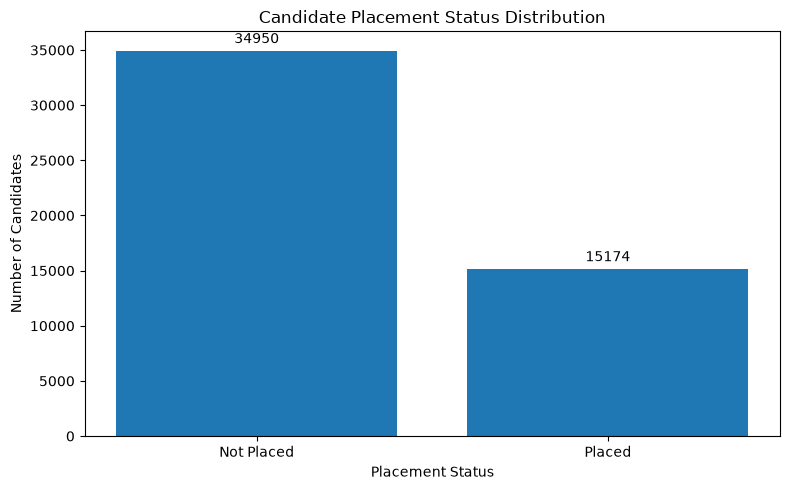

In [16]:
status_counts = df["status"].value_counts()
plt.figure(figsize=(8, 5))
bars = plt.bar(status_counts.index, status_counts.values)
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Candidate Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()


status        Not Placed  Placed
company_tier                    
Tier 1             70.07   29.93
Tier 1             69.59   30.41
Tier 2             69.65   30.35
Tier 2             67.64   32.36
Tier 3             69.38   30.62
Tier 3             71.29   28.71


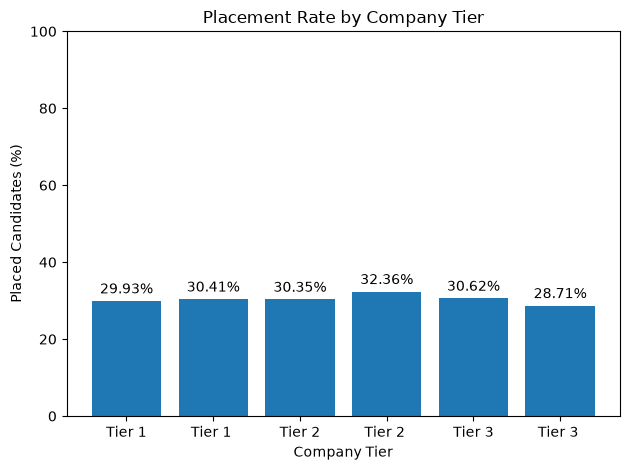

In [17]:
placement_by_tier = pd.crosstab(
    df["company_tier"],
    df["status"],
    normalize="index"
) * 100
print(placement_by_tier.round(2))
placed_pct = placement_by_tier["Placed"]
bars = plt.bar(placed_pct.index, placed_pct.values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Placement Rate by Company Tier")
plt.xlabel("Company Tier")
plt.ylabel("Placed Candidates (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [18]:
for value in df["company_tier"].dropna().unique():
    print(repr(value), df["company_tier"].eq(value).sum())

'Tier 3' 11727
'Tier 1' 18526
'Tier 2' 17780
'Tier 2 ' 754
'Tier 3 ' 505
'Tier 1 ' 832


In [19]:
df["company_tier"] = df["company_tier"].str.strip()
print(df["company_tier"].value_counts())

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64


status        Not Placed  Placed
company_tier                    
Tier 1             70.05   29.95
Tier 2             69.57   30.43
Tier 3             69.46   30.54


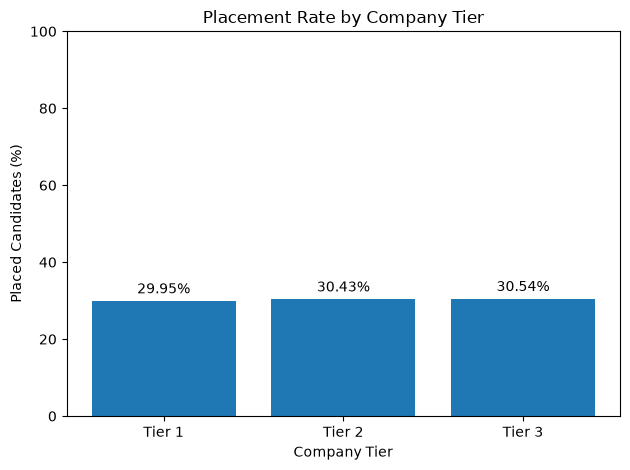

In [20]:
placement_by_tier = pd.crosstab(
    df["company_tier"],
    df["status"],
    normalize="index"
) * 100
print(placement_by_tier.round(2))
placed_pct = placement_by_tier["Placed"]
bars = plt.bar(placed_pct.index, placed_pct.values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Placement Rate by Company Tier")
plt.xlabel("Company Tier")
plt.ylabel("Placed Candidates (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

relevant_experience
Relevant        25597
Not Relevant    16328
NaN              8199
Name: count, dtype: int64

Placement rate by relevant experience:
status               Not Placed  Placed
relevant_experience                    
Not Relevant              76.80   23.20
Relevant                  63.69   36.31


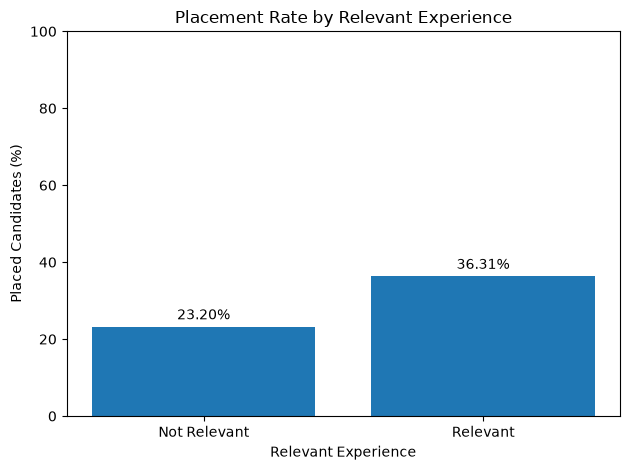

In [21]:
print(df["relevant_experience"].value_counts(dropna=False))
experience_placement = pd.crosstab(
    df["relevant_experience"],
    df["status"],
    normalize="index"
) * 100
print("\nPlacement rate by relevant experience:")
print(experience_placement.round(2))
placed_pct = experience_placement["Placed"]
bars = plt.bar(placed_pct.index.astype(str), placed_pct.values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Placement Rate by Relevant Experience")
plt.xlabel("Relevant Experience")
plt.ylabel("Placed Candidates (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


            count  mean  median    min    max
status                                       
Not Placed  34950  72.4   72.58  45.00  100.0
Placed      15174  77.5   77.23  55.01  100.0


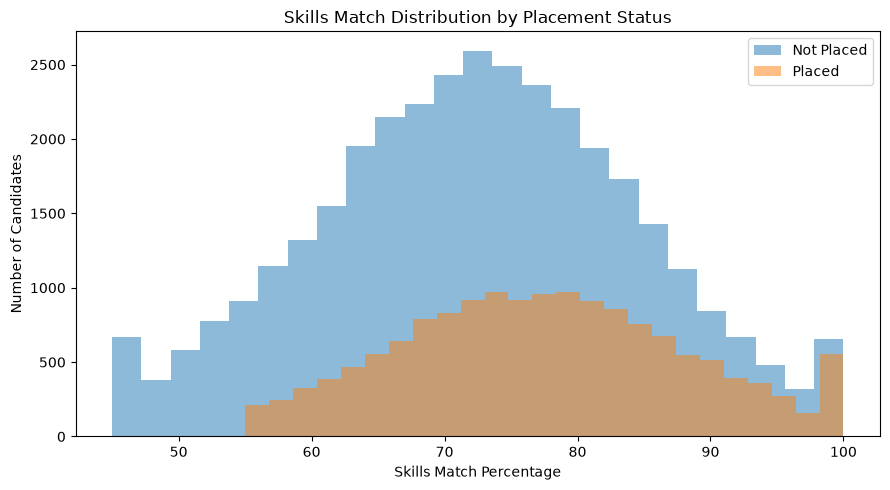

In [22]:
skills_analysis = (
    df.groupby("status")["skills_match_percentage"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)
print(skills_analysis)
plt.figure(figsize=(9, 5))
for status in df["status"].dropna().unique():
    values = df.loc[
        df["status"] == status,
        "skills_match_percentage"
    ].dropna()
    plt.hist(values, bins=25, alpha=0.5, label=status)
plt.title("Skills Match Distribution by Placement Status")
plt.xlabel("Skills Match Percentage")
plt.ylabel("Number of Candidates")
plt.legend()
plt.tight_layout()
plt.show()

internship_experience
No      24902
Yes     22715
 no      1314
yes      1193
Name: count, dtype: int64

Placement rate by internship experience:
status                 Not Placed  Placed
internship_experience                    
 no                         75.49   24.51
No                          75.92   24.08
Yes                         62.81   37.19
yes                         65.72   34.28


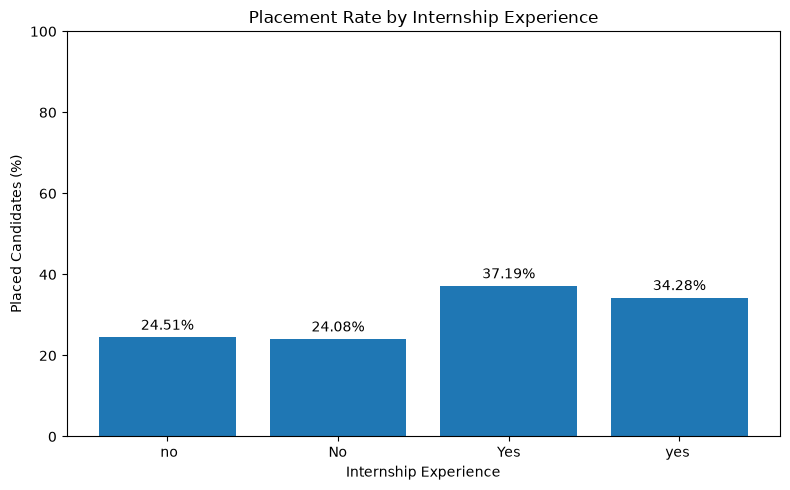

In [23]:
print(df["internship_experience"].value_counts(dropna=False))
internship_placement = pd.crosstab(
    df["internship_experience"],
    df["status"],
    normalize="index"
) * 100
print("\nPlacement rate by internship experience:")
print(internship_placement.round(2))
placed_pct = internship_placement["Placed"]
plt.figure(figsize=(8, 5))
bars = plt.bar(placed_pct.index.astype(str), placed_pct.values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Placement Rate by Internship Experience")
plt.xlabel("Internship Experience")
plt.ylabel("Placed Candidates (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [24]:
df["internship_experience"] = (
    df["internship_experience"]
    .str.strip()
    .str.lower()
)
print(df["internship_experience"].value_counts(dropna=False))

internship_experience
no     26216
yes    23908
Name: count, dtype: int64


status                 Not Placed  Placed
internship_experience                    
no                          75.90   24.10
yes                         62.96   37.04


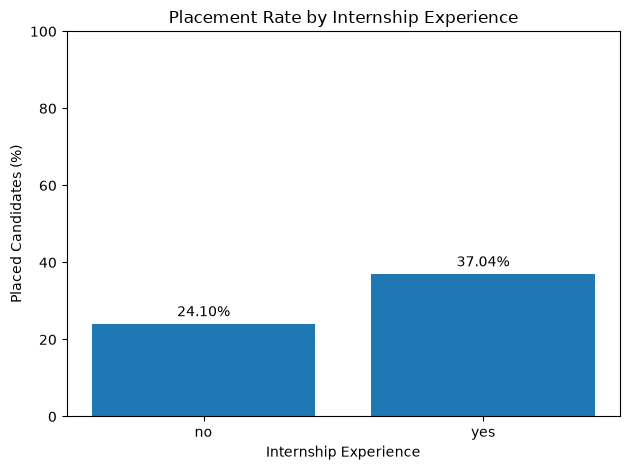

In [25]:

internship_placement = pd.crosstab(
    df["internship_experience"],
    df["status"],
    normalize="index"
) * 100
print(internship_placement.round(2))
placed_pct = internship_placement["Placed"]
bars = plt.bar(placed_pct.index, placed_pct.values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Placement Rate by Internship Experience")
plt.xlabel("Internship Experience")
plt.ylabel("Placed Candidates (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

            count  mean  median  min  max
status                                   
Not Placed  34950  1.40     1.0    0    8
Placed      15174  1.39     1.0    0    8


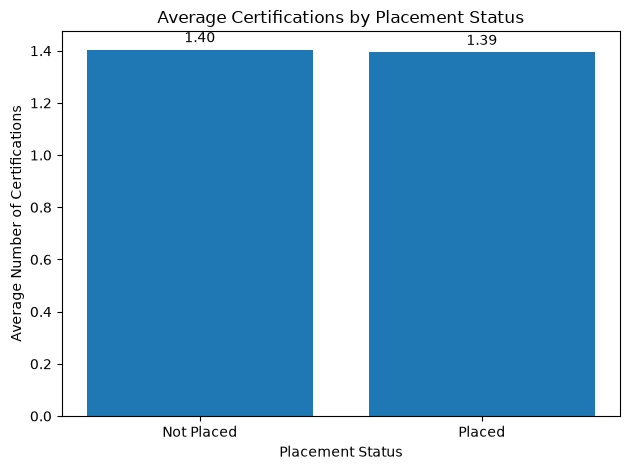

In [26]:
certification_analysis = (
    df.groupby("status")["certifications_count"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)
print(certification_analysis)
certification_means = (
    df.groupby("status")["certifications_count"].mean()
)
bars = plt.bar(
    certification_means.index,
    certification_means.values
)
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.title("Average Certifications by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average Number of Certifications")
plt.tight_layout()
plt.show()

In [27]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})
missing_report = (
    missing_report[missing_report["Missing_Count"] > 0]
    .sort_values("Missing_Count", ascending=False)
)
print(missing_report.to_string())

                           Missing_Count  Missing_Percentage
layoff_history                      8259               16.48
relocation_willingness              8247               16.45
career_switch_willingness           8242               16.44
relevant_experience                 8199               16.36
job_role_match                      5964               11.90
ssc_percentage                      2509                5.01
hsc_percentage                      2006                4.00
notice_period_days                  1538                3.07
employment_gap_months               1074                2.14


In [28]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()
print("Numerical columns:")
print(numerical_columns)
print("\nCategorical columns:")
print(categorical_columns)
print("\nData types:")
print(df.dtypes.to_string())

Numerical columns:
['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months']

Categorical columns:
['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'status']

Data types:
age_years                      int64
gender                           str
ssc_percentage               float64
hsc_percentage               float64
degree_percentage            float64
degree_specialization            str
technical_score              float64
aptitude_score               float64
communication_score          float64
skills_match_percentage      float64
certifications_count           int64
inter

In [31]:
numeric_summary = df[numerical_columns].describe().T
print(
    numeric_summary[
        ["count", "mean", "min", "25%", "50%", "75%", "max"]
    ].round(2).to_string()
)

                           count   mean   min    25%    50%    75%     max
age_years                50124.0  27.51  21.0  24.00  27.00  31.00   34.00
ssc_percentage           47615.0  70.01  50.0  64.58  69.98  75.40   95.00
hsc_percentage           48118.0  72.06  50.0  66.71  72.02  77.40   95.00
degree_percentage        50124.0  74.01  55.0  69.29  73.99  78.71   95.00
technical_score          50124.0  68.04  40.0  59.95  68.00  76.07  100.00
aptitude_score           50124.0  63.99  40.0  57.20  63.95  70.70  100.00
communication_score      50124.0  66.10  45.0  59.26  66.02  72.84  100.00
skills_match_percentage  50124.0  73.94  45.0  65.86  74.00  82.12  100.00
certifications_count     50124.0   1.40   0.0   1.00   1.00   2.00    8.00
years_of_experience      50124.0   1.49   0.0   0.00   1.00   2.00    5.00
previous_ctc_lpa         50124.0   4.84   1.0   3.32   4.81   6.30   13.84
expected_ctc_lpa         50124.0   8.00   3.0   5.67   7.86  10.09   26.52
notice_period_days       

In [32]:
percentage_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage"
]
for col in percentage_columns:
    invalid = df[col].notna() & ~df[col].between(0, 100)
    print(f"{col}: {invalid.sum()} invalid values")
nonnegative_columns = [
    "age_years",
    "certifications_count",
    "years_of_experience",
    "previous_ctc_lpa",
    "expected_ctc_lpa",
    "notice_period_days",
    "employment_gap_months"
]
for col in nonnegative_columns:
    invalid = df[col].notna() & (df[col] < 0)
    print(f"{col}: {invalid.sum()} negative values")

ssc_percentage: 0 invalid values
hsc_percentage: 0 invalid values
degree_percentage: 0 invalid values
technical_score: 0 invalid values
aptitude_score: 0 invalid values
communication_score: 0 invalid values
skills_match_percentage: 0 invalid values
age_years: 0 negative values
certifications_count: 0 negative values
years_of_experience: 0 negative values
previous_ctc_lpa: 0 negative values
expected_ctc_lpa: 0 negative values
notice_period_days: 0 negative values
employment_gap_months: 0 negative values


In [33]:
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- gender ---
gender
Female    23701
Male      23416
female     1504
male       1503
Name: count, dtype: int64

--- degree_specialization ---
degree_specialization
Others                    10174
Electronics               10078
Information Technology    10032
Computer Science           9927
Mechanical                 9913
Name: count, dtype: int64

--- internship_experience ---
internship_experience
no     26216
yes    23908
Name: count, dtype: int64

--- career_switch_willingness ---
career_switch_willingness
Not Willing    27707
Willing        14175
NaN             8242
Name: count, dtype: int64

--- relevant_experience ---
relevant_experience
Relevant        25597
Not Relevant    16328
NaN              8199
Name: count, dtype: int64

--- company_tier ---
company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64

--- job_role_match ---
job_role_match
Matched        32557
Not Matched    11603
NaN             5964
Name: count, dtype: int64

--- competitio

In [34]:
for col in categorical_columns:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())


--- gender ---
gender
female    25205
male      24919

--- degree_specialization ---
degree_specialization
others                    10174
electronics               10078
information technology    10032
computer science           9927
mechanical                 9913

--- internship_experience ---
internship_experience
no     26216
yes    23908

--- career_switch_willingness ---
career_switch_willingness
not willing    27707
willing        14175
NaN             8242

--- relevant_experience ---
relevant_experience
relevant        25597
not relevant    16328
NaN              8199

--- company_tier ---
company_tier
tier 1    19358
tier 2    18534
tier 3    12232

--- job_role_match ---
job_role_match
matched        32557
not matched    11603
NaN             5964

--- competition_level ---
competition_level
low       20891
medium    19165
high      10068

--- bond_requirement ---
bond_requirement
not required    39164
required        10960

--- layoff_history ---
layoff_history
no     363

In [35]:
columns_to_check = [
    "relevant_experience",
    "job_role_match",
    "competition_level",
    "bond_requirement",
    "layoff_history",
    "relocation_willingness"
]
for col in columns_to_check:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())


--- relevant_experience ---
relevant_experience
relevant        25597
not relevant    16328
NaN              8199

--- job_role_match ---
job_role_match
matched        32557
not matched    11603
NaN             5964

--- competition_level ---
competition_level
low       20891
medium    19165
high      10068

--- bond_requirement ---
bond_requirement
not required    39164
required        10960

--- layoff_history ---
layoff_history
no     36328
NaN     8259
yes     5537

--- relocation_willingness ---
relocation_willingness
willing        27061
not willing    14816
NaN             8247


In [36]:
print(df["layoff_history"].value_counts(dropna=False).to_string())

layoff_history
no     36328
NaN     8259
yes     5537


In [40]:
X = df.drop(columns=["status"])
y = df["status"]

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (40099, 25)
Testing features: (10025, 25)

Training target distribution:
status
not placed    0.697
placed        0.303
Name: proportion, dtype: float64

Testing target distribution:
status
not placed    0.697
placed        0.303
Name: proportion, dtype: float64


In [42]:
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical features: 14
Categorical features: 11
Preprocessing pipeline created successfully!


In [43]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


Accuracy: 0.8813
ROC-AUC: 0.9456

Classification Report:
              precision    recall  f1-score   support

  not placed       0.90      0.93      0.92      6990
      placed       0.82      0.77      0.80      3035

    accuracy                           0.88     10025
   macro avg       0.86      0.85      0.86     10025
weighted avg       0.88      0.88      0.88     10025



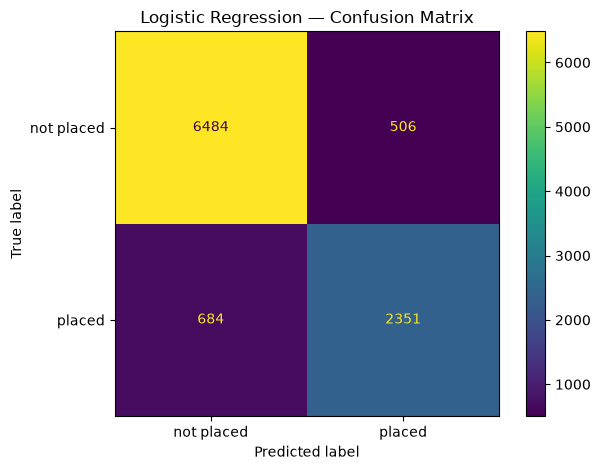

In [44]:

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[
    :, list(model.named_steps["classifier"].classes_).index("placed")
]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(
    (y_test == "placed").astype(int),
    y_prob
), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["not placed", "placed"],
    values_format="d"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [46]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Baseline accuracy:", round(
    accuracy_score(y_test, baseline_pred), 4
))
print("\nBaseline classification report:")
print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))
print("Logistic Regression accuracy:", round(
    accuracy_score(y_test, model.predict(X_test)), 4
))

Baseline accuracy: 0.6973

Baseline classification report:
              precision    recall  f1-score   support

  not placed       0.70      1.00      0.82      6990
      placed       0.00      0.00      0.00      3035

    accuracy                           0.70     10025
   macro avg       0.35      0.50      0.41     10025
weighted avg       0.49      0.70      0.57     10025

Logistic Regression accuracy: 0.8813


In [47]:

from sklearn.metrics import precision_score, recall_score, f1_score
threshold_results = []
for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (y_prob >= threshold).astype(int)
    actual = (y_test == "placed").astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(actual, pred, zero_division=0),
        "Recall": recall_score(actual, pred, zero_division=0),
        "F1_Score": f1_score(actual, pred, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1_Score
       0.3      0.724   0.889     0.798
       0.4      0.775   0.832     0.802
       0.5      0.823   0.775     0.798
       0.6      0.850   0.701     0.768
       0.7      0.875   0.617     0.724


In [50]:
models = {
    "Logistic Regression": model,
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}
results = []
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)
    classes = list(estimator.named_steps["classifier"].classes_)
    placed_index = classes.index("placed")
    probabilities = estimator.predict_proba(X_test)[:, placed_index]
    actual = (y_test == "placed").astype(int)
    predicted = (predictions == "placed").astype(int)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1_Score": f1_score(actual, predicted),
        "ROC_AUC": roc_auc_score(actual, probabilities)
    })
results_df = pd.DataFrame(results).sort_values(
    "F1_Score", ascending=False
)
print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
      Random Forest    0.8879     0.7679  0.9025    0.8297   0.9640
Logistic Regression    0.8813     0.8229  0.7746    0.7980   0.9456
      Decision Tree    0.8354     0.7371  0.7094    0.7230   0.9095


                          Feature  Importance
             num__technical_score    0.317126
         num__years_of_experience    0.138668
     num__skills_match_percentage    0.091091
            num__expected_ctc_lpa    0.059518
            num__previous_ctc_lpa    0.034726
      cat__job_role_match_matched    0.034386
         num__communication_score    0.034057
  cat__job_role_match_not matched    0.028106
              num__aptitude_score    0.020117
           num__degree_percentage    0.018738
              num__hsc_percentage    0.018105
              num__ssc_percentage    0.018057
   cat__internship_experience_yes    0.017953
cat__relevant_experience_relevant    0.017440
    cat__internship_experience_no    0.015454


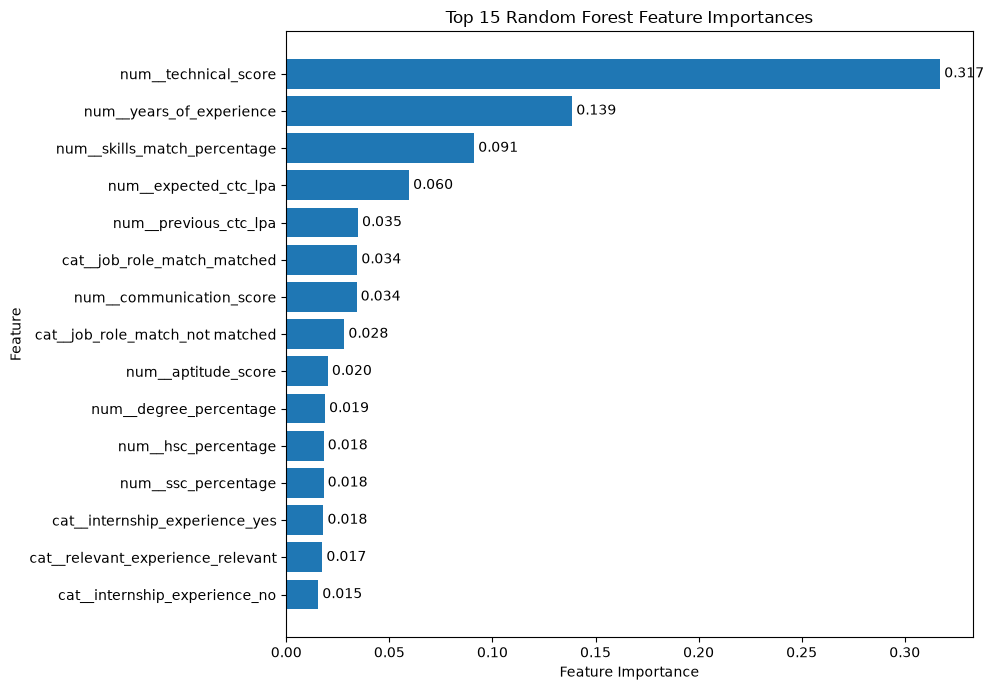

In [51]:
rf_model = models["Random Forest"]
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)
importances = rf_model.named_steps["classifier"].feature_importances_
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})
# Show the top 15 features
top_features = importance_df.sort_values(
    "Importance", ascending=False
).head(15)
print(top_features.to_string(index=False))
top_features = top_features.sort_values("Importance")
plt.figure(figsize=(10, 7))
bars = plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [52]:

X_sample = X_test.head(5)
predictions = models["Random Forest"].predict(X_sample)
probabilities = models["Random Forest"].predict_proba(X_sample)
classes = models["Random Forest"].named_steps["classifier"].classes_
placed_index = list(classes).index("placed")
results = pd.DataFrame({
    "Actual_Status": y_test.loc[X_sample.index],
    "Predicted_Status": predictions,
    "Placed_Probability": probabilities[:, placed_index].round(3)
})
print(results.to_string())

      Actual_Status Predicted_Status  Placed_Probability
30313        placed       not placed               0.398
13902        placed           placed               0.763
509      not placed       not placed               0.006
45908        placed           placed               0.919
24473    not placed       not placed               0.175


In [57]:
rf_model = models["Random Forest"]
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": make_scorer(
        recall_score,
        pos_label="placed"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="placed"
    ),
    "roc_auc": "roc_auc"
}
cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.8882 +/- 0.0012
precision: nan +/- nan
recall: 0.8961 +/- 0.0050
f1: 0.8292 +/- 0.0011
roc_auc: 0.9637 +/- 0.0009


In [58]:
rf_model = models["Random Forest"]
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="placed",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="placed",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="placed",
        zero_division=0
    ),
    "roc_auc": "roc_auc"
}
cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.8882 +/- 0.0012
precision: 0.7716 +/- 0.0048
recall: 0.8961 +/- 0.0050
f1: 0.8292 +/- 0.0011
roc_auc: 0.9637 +/- 0.0009


In [59]:
print(models["Random Forest"])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_years',
                                                   'ssc_percentage',
                                                   'hsc_percentage',
                                                   'degree_percentage',
                                                   'technical_score',
                                                   'aptitude_score',
                                                   'communication_score',
                                                   'skills_match_percentage',


In [60]:
print("Model:", type(models["Random Forest"]).__name__)
print("Classes:",
      models["Random Forest"].named_steps["classifier"].classes_)
print("Test accuracy:", 
      models["Random Forest"].score(X_test, y_test))

Model: Pipeline
Classes: ['not placed' 'placed']
Test accuracy: 0.8878802992518703


In [61]:
import pickle
with open("job_placement_model.pkl", "wb") as file:
    pickle.dump(models["Random Forest"], file)
print("Model saved successfully!")

Model saved successfully!


In [62]:
with open("job_placement_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)
print("Model loaded successfully!")
predictions = loaded_model.predict(X_test.head(5))
print("Predictions:", predictions)

Model loaded successfully!
Predictions: ['not placed' 'placed' 'not placed' 'placed' 'not placed']
